"""
Exemple jouet de reverse stress test (RST) - chiffres FICTIFS, pas les données UMR.
Modèle ALM simplifié à 1 an : actif (obligations, actions, immobilier) / passif (régime par points, PTS
valorisée en vision économique). Indicateur : taux de couverture C = Actif / Passif.
Trois seuils : cible 110 %, alerte 105 %, limite 100 %.
"""

In [4]:
pip install matplotlib

   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---- ----------------------------------- 1.0/9.3 MB 5.8 MB/s eta 0:00:02
   ---------- ----------------------------- 2.4/9.3 MB 6.3 MB/s eta 0:00:02
   ------------- -------------------------- 3.1/9.3 MB 5.4 MB/s eta 0:00:02
   ---------------- ----------------------- 3.9/9.3 MB 4.7 MB/s eta 0:00:02
   ------------------- -------------------- 4.5/9.3 MB 4.4 MB/s eta 0:00:02
   --------------------- ------------------ 5.0/9.3 MB 4.1 MB/s eta 0:00:02
   ------------------------- -------------- 6.0/9.3 MB 4.1 MB/s eta 0:00:01
   ----------------------------- ---------- 6.8/9.3 MB 4.0 MB/s eta 0:00:01
   -------------------------------- ------- 7.6/9.3 MB 4.0 MB/s eta 0:00:01
   ------------------------------------- -- 8.7/9.3 MB 4.0 MB/s eta 0:00:01
   ---------------------------------------  9.2/9.3 MB 4.0 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 3.9 MB/s  0:00:02
   -------------------


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:

import numpy as np
from scipy import optimize, stats
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)

Matplotlib is building the font cache; this may take a moment.


In [6]:
# ---------- 1. Modèle ALM jouet (la "boîte noire" f) ----------
A_OBL, A_ACT, A_IMM = 700.0, 200.0, 100.0      # actif initial (M€)
DUR_A, CONV_A = 8.0, 80.0                        # duration / convexité obligataire
L0, DUR_L, CONV_L = 850.0, 14.0, 250.0           # passif initial, duration > actif
SENS_LONG = 0.30                                  # -10 % de mortalité => +3 % de passif

def alm(dr, eq, imm, longv, put_strike=None):
    """Retourne le taux de couverture pour un scénario (vectorisé)."""
    obl = A_OBL * (1 - DUR_A * dr + 0.5 * CONV_A * dr**2)
    act = A_ACT * (1 + eq)
    if put_strike is not None:                    # couverture : put sur actions
        act = A_ACT * (1 + np.maximum(eq, put_strike)) - A_ACT * 0.012   # prime 1,2 %
    actif = obl + act + A_IMM * (1 + imm)
    passif = L0 * (1 - DUR_L * dr + 0.5 * CONV_L * dr**2) * (1 + SENS_LONG * longv)
    return actif / passif

In [7]:
# ---------- 2. Loi des facteurs de risque (1 an) ----------
names = ["Taux (pb)", "Actions", "Immobilier", "Longévité"]
sd = np.array([0.0080, 0.18, 0.08, 0.04])         # 80 pb, 18 %, 8 %, 4 %
corr = np.array([[1.0, 0.30, 0.20, 0.0],
                 [0.30, 1.0, 0.50, 0.0],
                 [0.20, 0.50, 1.0, 0.0],
                 [0.0, 0.0, 0.0, 1.0]])
Sigma = np.outer(sd, sd) * corr
Sinv = np.linalg.inv(Sigma)
# longévité : seule la baisse de mortalité est défavorable => on garde le signe (variable centrée)

# Tirage via copule de Student (dépendance de queue), marges normales
N, nu = 200_000, 5
Lc = np.linalg.cholesky(corr)
z = rng.standard_normal((N, 4)) @ Lc.T
w = rng.chisquare(nu, N) / nu
u = stats.t.cdf(z / np.sqrt(w)[:, None], nu)
X = stats.norm.ppf(u) * sd
C = alm(*X.T)
C0 = alm(0, 0, 0, 0)


seuils = {"Cible 110 %": 1.10, "Alerte 105 %": 1.05, "Limite 100 %": 1.00}

In [8]:


# ---------- 3. RST : scénario le plus plausible (optimisation) ----------
def plus_plausible(s, **kw):
    cons = {"type": "eq", "fun": lambda x: alm(*x, **kw) - s}
    best = None
    for x0 in rng.standard_normal((20, 4)) * sd * 2:
        r = optimize.minimize(lambda x: x @ Sinv @ x, x0, constraints=[cons], method="SLSQP")
        if r.success and (best is None or r.fun < best.fun):
            best = r
    return best.x, np.sqrt(best.fun)

def resume(Cs, Xs, label, **kw):
    print(f"\n=== {label} ===  couverture initiale : {alm(0,0,0,0,**kw):.1%}")
    out = {}
    for nom, s in seuils.items():
        mask = Cs < s
        xs, d = plus_plausible(s, **kw)
        out[nom] = (mask.mean(), xs, Xs[mask].mean(axis=0) if mask.any() else None)
        print(f"{nom:13s} P(franchissement)={mask.mean():6.2%} | scénario le + plausible : "
              f"taux {xs[0]*1e4:+5.0f} pb, actions {xs[1]:+6.1%}, immo {xs[2]:+6.1%}, "
              f"longévité {xs[3]:+5.1%} (distance de Mahalanobis {d:.2f})")
    return out

res = resume(C, X, "Sans couverture")


=== Sans couverture ===  couverture initiale : 117.6%
Cible 110 %   P(franchissement)=22.00% | scénario le + plausible : taux   -54 pb, actions  -9.1%, immo  -2.7%, longévité +0.4% (distance de Mahalanobis 0.75)
Alerte 105 %  P(franchissement)= 9.68% | scénario le + plausible : taux   -91 pb, actions -15.5%, immo  -4.5%, longévité +0.7% (distance de Mahalanobis 1.28)
Limite 100 %  P(franchissement)= 3.41% | scénario le + plausible : taux  -131 pb, actions -22.3%, immo  -6.5%, longévité +1.0% (distance de Mahalanobis 1.84)


In [9]:

# ---------- 4. Décision : couverture actions (put strike -20 %) puis relance du RST ----------
C_h = alm(*X.T, put_strike=-0.20)
res_h = resume(C_h, X, "Avec put actions (strike -20 %)", put_strike=-0.20)


=== Avec put actions (strike -20 %) ===  couverture initiale : 117.4%
Cible 110 %   P(franchissement)=21.81% | scénario le + plausible : taux   -52 pb, actions  -8.8%, immo  -2.6%, longévité +0.4% (distance de Mahalanobis 0.73)
Alerte 105 %  P(franchissement)= 8.98% | scénario le + plausible : taux   -89 pb, actions -15.2%, immo  -4.4%, longévité +0.7% (distance de Mahalanobis 1.25)
Limite 100 %  P(franchissement)= 2.59% | scénario le + plausible : taux  -134 pb, actions -20.0%, immo  -6.1%, longévité +1.1% (distance de Mahalanobis 1.82)


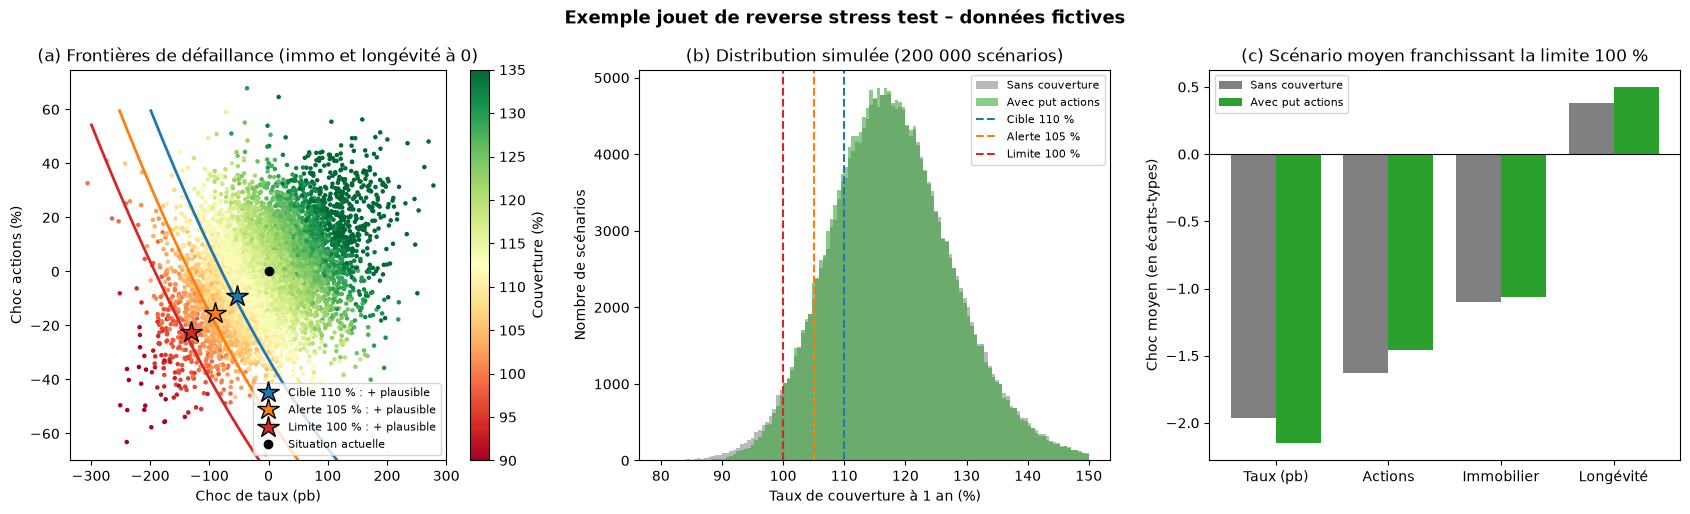

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(17, 5.2))
# (a) région de défaillance dans le plan taux / actions
idx = rng.choice(N, 6000, replace=False)
sc = ax[0].scatter(X[idx, 0]*1e4, X[idx, 1]*100, c=C[idx]*100, cmap="RdYlGn", s=5, vmin=90, vmax=135)
gr, ge = np.meshgrid(np.linspace(-300, 300, 300), np.linspace(-70, 60, 300))
cols = ["#1f77b4", "#ff7f0e", "#d62728"]
for (nom, s), col in zip(seuils.items(), cols):
    ax[0].contour(gr, ge, alm(gr/1e4, ge/100, 0, 0), levels=[s], colors=[col], linewidths=2)
    xs = res[nom][1]
    ax[0].plot(xs[0]*1e4, xs[1]*100, "*", ms=16, color=col, mec="k", label=f"{nom} : + plausible")
ax[0].plot(0, 0, "ko", label="Situation actuelle")
ax[0].set(xlabel="Choc de taux (pb)", ylabel="Choc actions (%)",
          title="(a) Frontières de défaillance (immo et longévité à 0)")
ax[0].legend(fontsize=8, loc="lower right"); plt.colorbar(sc, ax=ax[0], label="Couverture (%)")
# (b) distribution de la couverture, avant / après couverture
b = np.linspace(80, 150, 120)
ax[1].hist(C*100, b, alpha=.55, label="Sans couverture", color="grey")
ax[1].hist(C_h*100, b, alpha=.55, label="Avec put actions", color="#2ca02c")
for (nom, s), col in zip(seuils.items(), cols):
    ax[1].axvline(s*100, color=col, ls="--", label=nom)
ax[1].set(xlabel="Taux de couverture à 1 an (%)", ylabel="Nombre de scénarios",
          title="(b) Distribution simulée (200 000 scénarios)"); ax[1].legend(fontsize=8)
# (c) profil moyen des scénarios qui franchissent la limite, avant/après
m0 = res["Limite 100 %"][2] / sd; m1 = res_h["Limite 100 %"][2] / sd
xx = np.arange(4)
ax[2].bar(xx-.2, m0, .4, label="Sans couverture", color="grey")
ax[2].bar(xx+.2, m1, .4, label="Avec put actions", color="#2ca02c")
ax[2].axhline(0, color="k", lw=.8); ax[2].set_xticks(xx, names)
ax[2].set(ylabel="Choc moyen (en écarts-types)",
          title="(c) Scénario moyen franchissant la limite 100 %"); ax[2].legend(fontsize=8)
fig.suptitle("Exemple jouet de reverse stress test – données fictives", fontsize=13, weight="bold")
fig.tight_layout()
fig.savefig("exemple_rst.png", dpi=130)   # enregistré dans le dossier courant
plt.show()
 